# Model Evaluation — So sánh các model PM2.5

Notebook này so sánh 5 model:
- Persistence (baseline)
- Ridge Regression
- LightGBM Exp1 (temporal only)
- LightGBM Exp2 (+weather)
- LightGBM Exp3 (Optuna, full features)

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import optuna
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Load data và models

In [2]:
# Load feature splits
train = pd.read_parquet(ROOT / "data/features/train.parquet")
val   = pd.read_parquet(ROOT / "data/features/val.parquet")
test  = pd.read_parquet(ROOT / "data/features/test.parquet")

print(f"Train: {len(train):,} rows  ({train['date'].min().date()} → {train['date'].max().date()})")
print(f"Val:   {len(val):,} rows  ({val['date'].min().date()} → {val['date'].max().date()})")
print(f"Test:  {len(test):,} rows  ({test['date'].min().date()} → {test['date'].max().date()})")

Train: 13,621 rows  (2022-01-16 → 2025-06-30)
Val:   4,076 rows  (2025-07-01 → 2025-09-30)
Test:  4,622 rows  (2025-10-01 → 2025-12-30)


In [3]:
# Load models
def load(name):
    with open(ROOT / f"models/{name}.pkl", "rb") as f:
        return pickle.load(f)

ridge    = load("ridge")
lgbm_e1  = load("lgbm_exp1")
lgbm_e2  = load("lgbm_exp2")
lgbm_e3  = load("lgbm_exp3_best")
study    = load("optuna_exp3")

print("Models loaded ✓")

Models loaded ✓


In [4]:
# Feature sets
TEMPORAL = [
    "pm25_lag1","pm25_lag2","pm25_lag3","pm25_lag7",
    "pm25_roll7_mean","pm25_roll14_mean","pm25_roll30_mean",
    "pm25_roll7_std","pm25_roll14_std",
    "month_sin","month_cos","dow_sin","dow_cos",
    "season_winter","season_spring","season_monsoon",
]
WEATHER    = ["temperature","wind_speed","wind_direction","precipitation","humidity","et0"]
INDUSTRIAL = ["dist_nearest_plant_km","capacity_weighted_dist","n_plants_50km"]
ALL_FEATS  = TEMPORAL + WEATHER + INDUSTRIAL

# Generate predictions
preds = {}
for split_name, df in [("val", val), ("test", test)]:
    preds[split_name] = {
        "y_true":       df["pm25_target"].values,
        "Persistence":  df["pm25_lag1"].values,
        "Ridge":        ridge.predict(df[ALL_FEATS]),
        "LightGBM Exp1": lgbm_e1.predict(df[TEMPORAL]),
        "LightGBM Exp2": lgbm_e2.predict(df[TEMPORAL + WEATHER]),
        "LightGBM Exp3": lgbm_e3.predict(df[ALL_FEATS]),
    }

# Compute metrics
def compute_metrics(y_true, y_pred):
    return {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2":   r2_score(y_true, y_pred),
    }

metrics = {}
for split_name in ["val", "test"]:
    y_true = preds[split_name]["y_true"]
    for model_name in ["Persistence", "Ridge", "LightGBM Exp1", "LightGBM Exp2", "LightGBM Exp3"]:
        metrics[(split_name, model_name)] = compute_metrics(y_true, preds[split_name][model_name])

# Summary table
rows = []
for (split, model), m in metrics.items():
    rows.append({"Split": split, "Model": model, **m})
df_metrics = pd.DataFrame(rows)
print(df_metrics.round(2).to_string(index=False))

Split         Model   MAE  RMSE    R2
  val   Persistence 11.10 16.81 -0.11
  val         Ridge 15.05 19.05 -0.43
  val LightGBM Exp1  9.96 14.04  0.22
  val LightGBM Exp2  9.68 13.69  0.26
  val LightGBM Exp3  9.34 13.33  0.30
 test   Persistence 54.25 75.77  0.32
 test         Ridge 48.83 65.04  0.50
 test LightGBM Exp1 51.88 71.29  0.40
 test LightGBM Exp2 45.13 62.00  0.54
 test LightGBM Exp3 45.42 63.14  0.53


## 2. So sánh MAE, RMSE, R² giữa các model

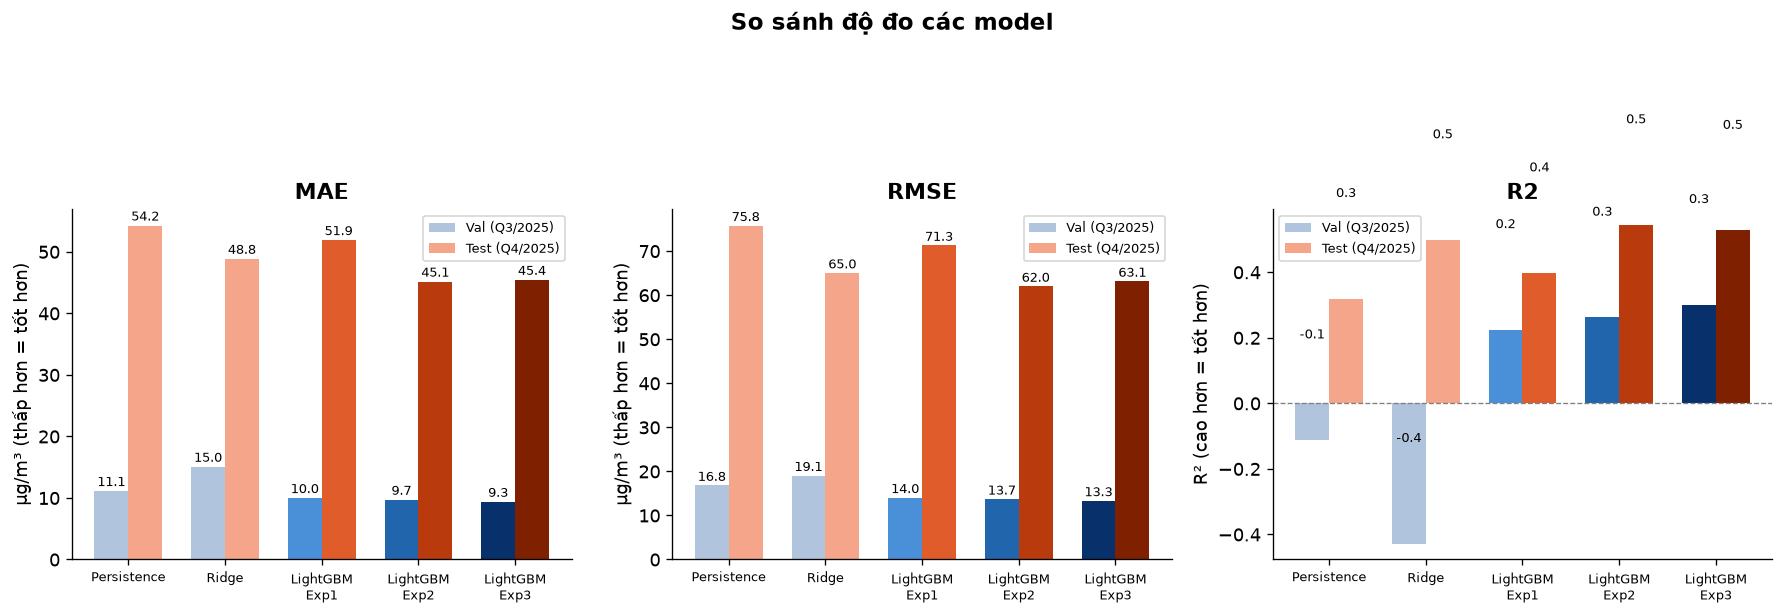

In [5]:
models     = ["Persistence", "Ridge", "LightGBM Exp1", "LightGBM Exp2", "LightGBM Exp3"]
colors_val  = ["#b0c4de"] * 2 + ["#4a90d9", "#2166ac", "#08306b"]
colors_test = ["#f4a58a"] * 2 + ["#e05c2a", "#b83a0d", "#7f2000"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("So sánh độ đo các model", fontsize=14, fontweight="bold", y=1.02)

for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    val_scores  = [metrics[("val",  m)][metric] for m in models]
    test_scores = [metrics[("test", m)][metric] for m in models]

    x = np.arange(len(models))
    w = 0.35
    bars1 = ax.bar(x - w/2, val_scores,  w, label="Val (Q3/2025)",  color=colors_val)
    bars2 = ax.bar(x + w/2, test_scores, w, label="Test (Q4/2025)", color=colors_test)

    # Ghi số lên đầu cột
    for bar in bars1:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f"{bar.get_height():.1f}", ha="center", va="bottom", fontsize=8)
    for bar in bars2:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f"{bar.get_height():.1f}", ha="center", va="bottom", fontsize=8)

    ax.set_title(metric, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace(" ", "\n") for m in models], fontsize=8)
    ax.legend(fontsize=8)

    if metric in ["MAE", "RMSE"]:
        ax.set_ylabel("µg/m³ (thấp hơn = tốt hơn)")
    else:
        ax.set_ylabel("R² (cao hơn = tốt hơn)")
        ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")

plt.tight_layout()
plt.savefig(ROOT / "reports/figures/model_comparison.png", bbox_inches="tight")
plt.show()

## 3. Ablation study — Đóng góp của từng nhóm feature

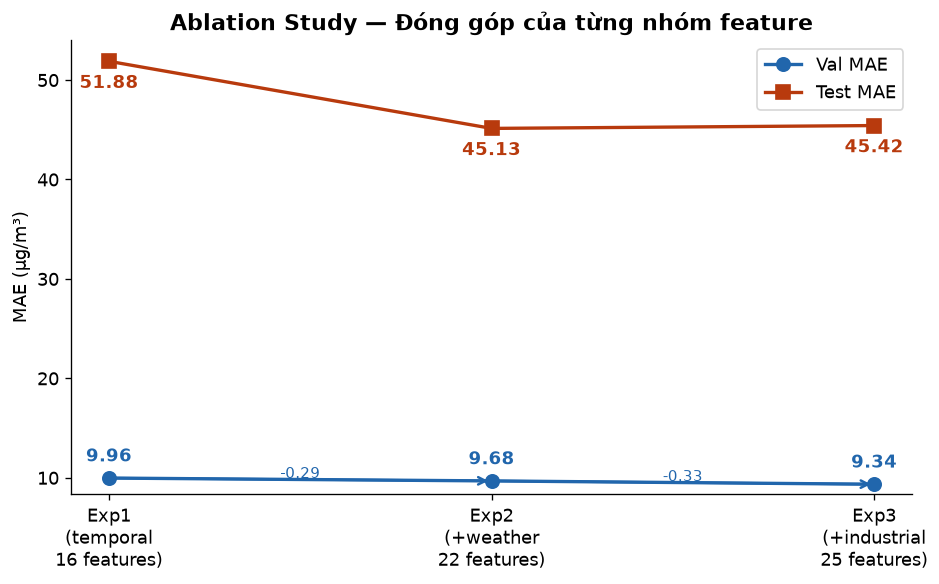

In [6]:
ablation_models = ["LightGBM Exp1", "LightGBM Exp2", "LightGBM Exp3"]
ablation_labels = ["Exp1\n(temporal\n16 features)", "Exp2\n(+weather\n22 features)", "Exp3\n(+industrial\n25 features)"]
val_mae  = [metrics[("val",  m)]["MAE"] for m in ablation_models]
test_mae = [metrics[("test", m)]["MAE"] for m in ablation_models]

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(3)
ax.plot(x, val_mae,  "o-", color="#2166ac", linewidth=2, markersize=8, label="Val MAE")
ax.plot(x, test_mae, "s-", color="#b83a0d", linewidth=2, markersize=8, label="Test MAE")

# Ghi số lên điểm
for i, (v, t) in enumerate(zip(val_mae, test_mae)):
    ax.annotate(f"{v:.2f}", (i, v), textcoords="offset points", xytext=(0, 10),
                ha="center", color="#2166ac", fontweight="bold")
    ax.annotate(f"{t:.2f}", (i, t), textcoords="offset points", xytext=(0, -16),
                ha="center", color="#b83a0d", fontweight="bold")

# Mũi tên chỉ mức cải thiện
for i in range(len(val_mae) - 1):
    delta = val_mae[i] - val_mae[i+1]
    ax.annotate("", xy=(i+1, val_mae[i+1]), xytext=(i, val_mae[i]),
                arrowprops=dict(arrowstyle="->", color="#2166ac", lw=1.5))
    ax.text(i + 0.5, (val_mae[i] + val_mae[i+1])/2 + 0.15,
            f"-{delta:.2f}", ha="center", color="#2166ac", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(ablation_labels)
ax.set_ylabel("MAE (µg/m³)")
ax.set_title("Ablation Study — Đóng góp của từng nhóm feature", fontweight="bold")
ax.legend()
ax.set_ylim(bottom=min(val_mae) - 1)

plt.tight_layout()
plt.savefig(ROOT / "reports/figures/ablation_study.png", bbox_inches="tight")
plt.show()

## 4. Actual vs Predicted — Model dự đoán sát thực tế không?

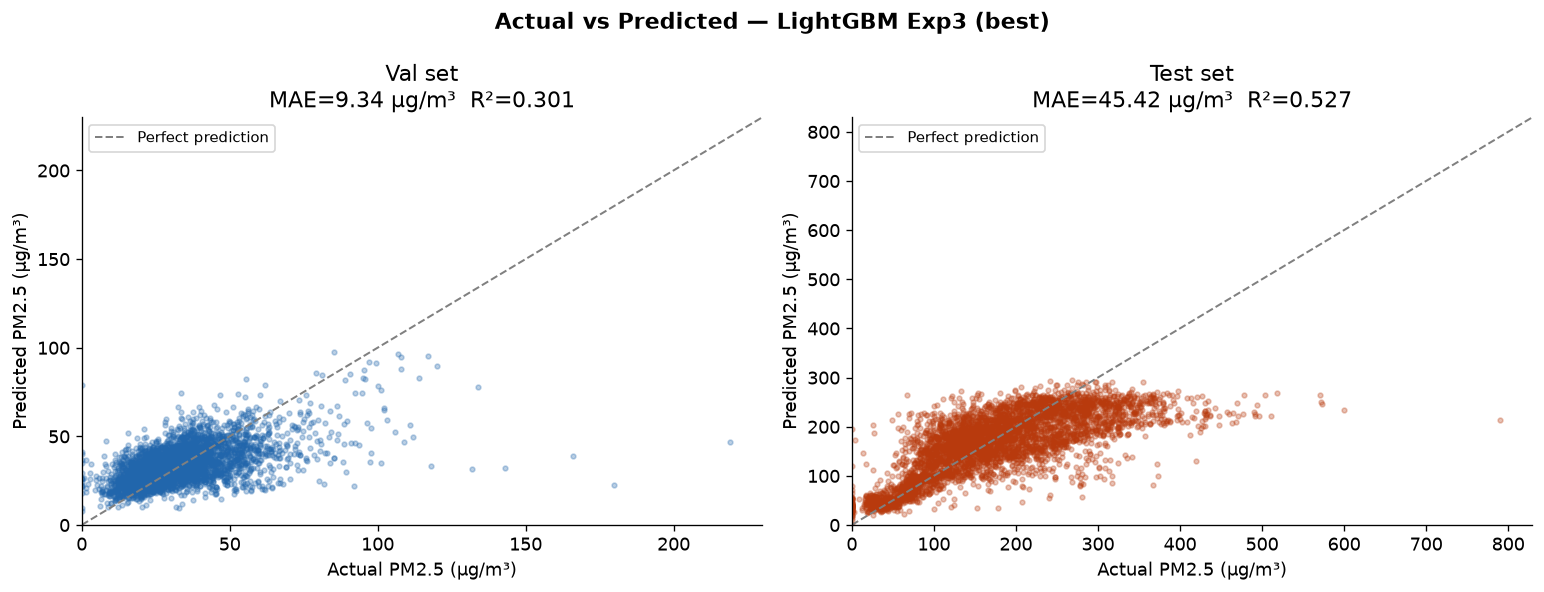

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Actual vs Predicted — LightGBM Exp3 (best)", fontweight="bold")

for ax, split_name, color in [(axes[0], "val", "#2166ac"), (axes[1], "test", "#b83a0d")]:
    y_true = preds[split_name]["y_true"]
    y_pred = preds[split_name]["LightGBM Exp3"]

    ax.scatter(y_true, y_pred, alpha=0.3, s=8, color=color)

    # Đường perfect prediction
    lim = max(y_true.max(), y_pred.max()) * 1.05
    ax.plot([0, lim], [0, lim], "--", color="gray", linewidth=1.2, label="Perfect prediction")

    mae  = metrics[(split_name, "LightGBM Exp3")]["MAE"]
    r2   = metrics[(split_name, "LightGBM Exp3")]["R2"]
    ax.set_title(f"{split_name.capitalize()} set\nMAE={mae:.2f} µg/m³  R²={r2:.3f}")
    ax.set_xlabel("Actual PM2.5 (µg/m³)")
    ax.set_ylabel("Predicted PM2.5 (µg/m³)")
    ax.legend(fontsize=9)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

plt.tight_layout()
plt.savefig(ROOT / "reports/figures/actual_vs_predicted.png", bbox_inches="tight")
plt.show()

## 5. Phân phối sai số (Residuals)

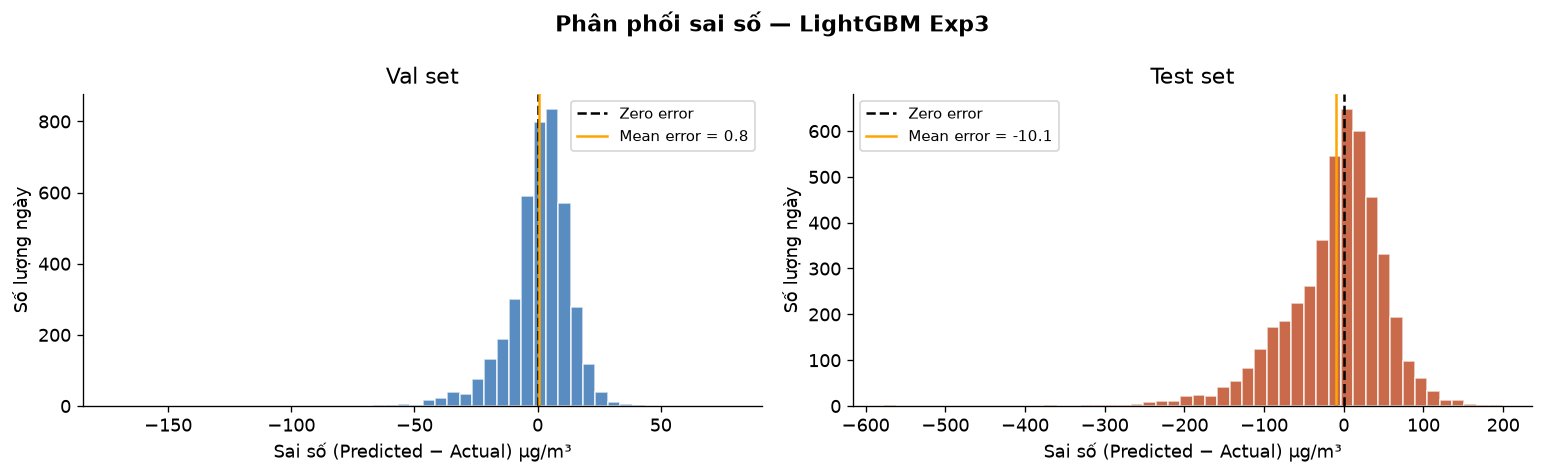


Val residuals:
  Mean  : 0.75  (dương = hay đoán cao hơn thực)
  Std   : 13.31
  Min   : -172.12
  Max   : 78.67


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Phân phối sai số — LightGBM Exp3", fontweight="bold")

for ax, split_name, color in [(axes[0], "val", "#2166ac"), (axes[1], "test", "#b83a0d")]:
    y_true = preds[split_name]["y_true"]
    y_pred = preds[split_name]["LightGBM Exp3"]
    residuals = y_pred - y_true  # dương = dự đoán cao hơn thực tế

    ax.hist(residuals, bins=50, color=color, alpha=0.75, edgecolor="white")
    ax.axvline(0,               color="black", linewidth=1.5, linestyle="--", label="Zero error")
    ax.axvline(residuals.mean(), color="orange", linewidth=1.5, linestyle="-",
               label=f"Mean error = {residuals.mean():.1f}")

    ax.set_xlabel("Sai số (Predicted − Actual) µg/m³")
    ax.set_ylabel("Số lượng ngày")
    ax.set_title(f"{split_name.capitalize()} set")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(ROOT / "reports/figures/residuals.png", bbox_inches="tight")
plt.show()

print("\nVal residuals:")
r = preds["val"]["LightGBM Exp3"] - preds["val"]["y_true"]
print(f"  Mean  : {r.mean():.2f}  (dương = hay đoán cao hơn thực)")
print(f"  Std   : {r.std():.2f}")
print(f"  Min   : {r.min():.2f}")
print(f"  Max   : {r.max():.2f}")

## 6. Feature Importance — Feature nào quan trọng nhất?

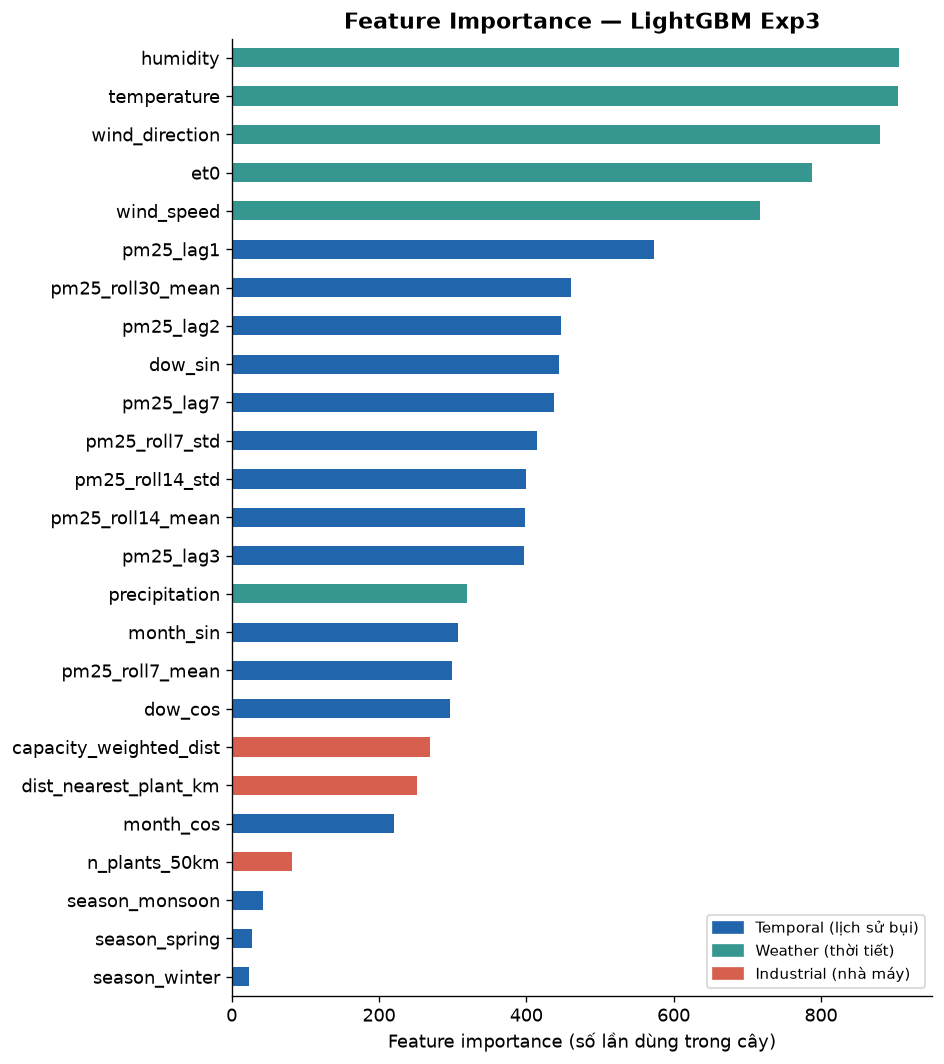

In [9]:
importance = pd.Series(
    lgbm_e3.feature_importances_,
    index=ALL_FEATS
).sort_values(ascending=True)

# Màu theo nhóm feature
group_color = {}
for f in TEMPORAL:    group_color[f] = "#2166ac"
for f in WEATHER:     group_color[f] = "#35978f"
for f in INDUSTRIAL:  group_color[f] = "#d6604d"
bar_colors = [group_color[f] for f in importance.index]

fig, ax = plt.subplots(figsize=(8, 9))
importance.plot(kind="barh", ax=ax, color=bar_colors)

# Legend nhóm
from matplotlib.patches import Patch
legend_items = [
    Patch(color="#2166ac", label="Temporal (lịch sử bụi)"),
    Patch(color="#35978f", label="Weather (thời tiết)"),
    Patch(color="#d6604d", label="Industrial (nhà máy)"),
]
ax.legend(handles=legend_items, loc="lower right", fontsize=9)
ax.set_xlabel("Feature importance (số lần dùng trong cây)")
ax.set_title("Feature Importance — LightGBM Exp3", fontweight="bold")

plt.tight_layout()
plt.savefig(ROOT / "reports/figures/feature_importance.png", bbox_inches="tight")
plt.show()

## 7. Optuna — Quá trình tìm hyperparameter

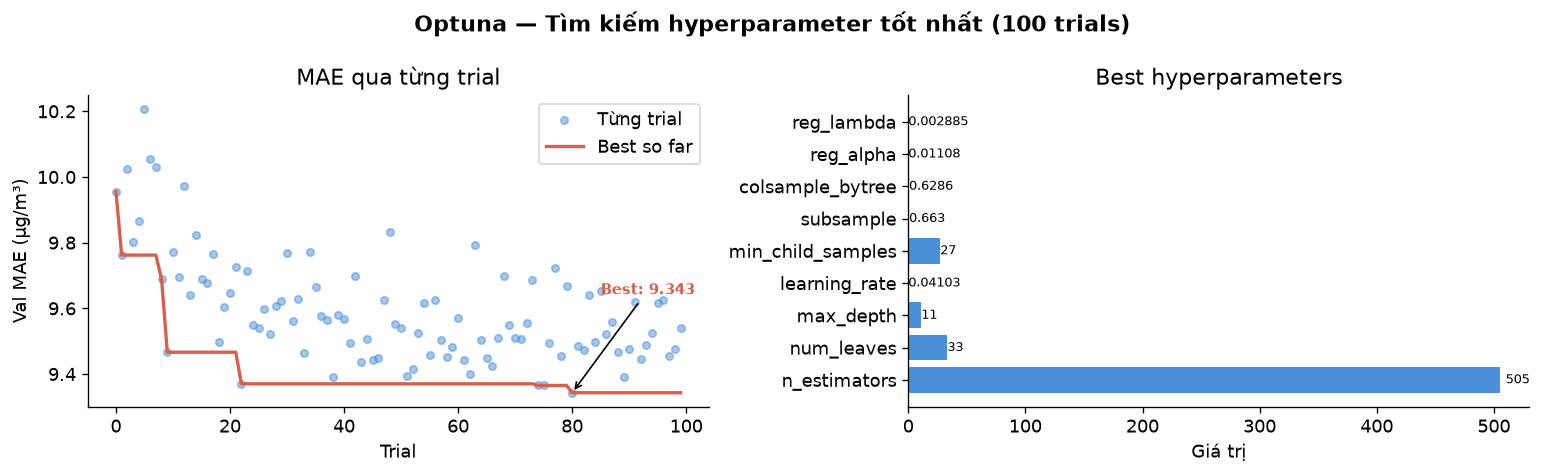


Best trial: #80
Best val MAE: 9.3427 µg/m³

Best params:
  n_estimators         = 505
  num_leaves           = 33
  max_depth            = 11
  learning_rate        = 0.0410269
  min_child_samples    = 27
  subsample            = 0.663017
  colsample_bytree     = 0.628588
  reg_alpha            = 0.0110799
  reg_lambda           = 0.00288501


In [10]:
trial_nums  = [t.number for t in study.trials]
trial_vals  = [t.value  for t in study.trials]

# Best value tại mỗi trial
best_so_far = np.minimum.accumulate(trial_vals)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Optuna — Tìm kiếm hyperparameter tốt nhất (100 trials)", fontweight="bold")

# Plot 1: Từng trial
axes[0].scatter(trial_nums, trial_vals, alpha=0.5, s=20, color="#4a90d9", label="Từng trial")
axes[0].plot(trial_nums, best_so_far, color="#d6604d", linewidth=2, label="Best so far")
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Val MAE (µg/m³)")
axes[0].set_title("MAE qua từng trial")
axes[0].legend()
axes[0].annotate(f"Best: {study.best_value:.3f}",
                 xy=(study.best_trial.number, study.best_value),
                 xytext=(study.best_trial.number + 5, study.best_value + 0.3),
                 arrowprops=dict(arrowstyle="->", color="black"),
                 fontsize=9, color="#d6604d", fontweight="bold")

# Plot 2: Top hyperparameters của best trial
best_params = study.best_params
param_names = list(best_params.keys())
param_vals  = list(best_params.values())
axes[1].barh(param_names, param_vals, color="#4a90d9")
for i, v in enumerate(param_vals):
    axes[1].text(v * 1.01, i, f"{v:.4g}", va="center", fontsize=8)
axes[1].set_title("Best hyperparameters")
axes[1].set_xlabel("Giá trị")

plt.tight_layout()
plt.savefig(ROOT / "reports/figures/optuna_history.png", bbox_inches="tight")
plt.show()

print(f"\nBest trial: #{study.best_trial.number}")
print(f"Best val MAE: {study.best_value:.4f} µg/m³")
print("\nBest params:")
for k, v in best_params.items():
    print(f"  {k:20s} = {v:.6g}")

## 8. Dự đoán theo thời gian — Model bám sát thực tế không?

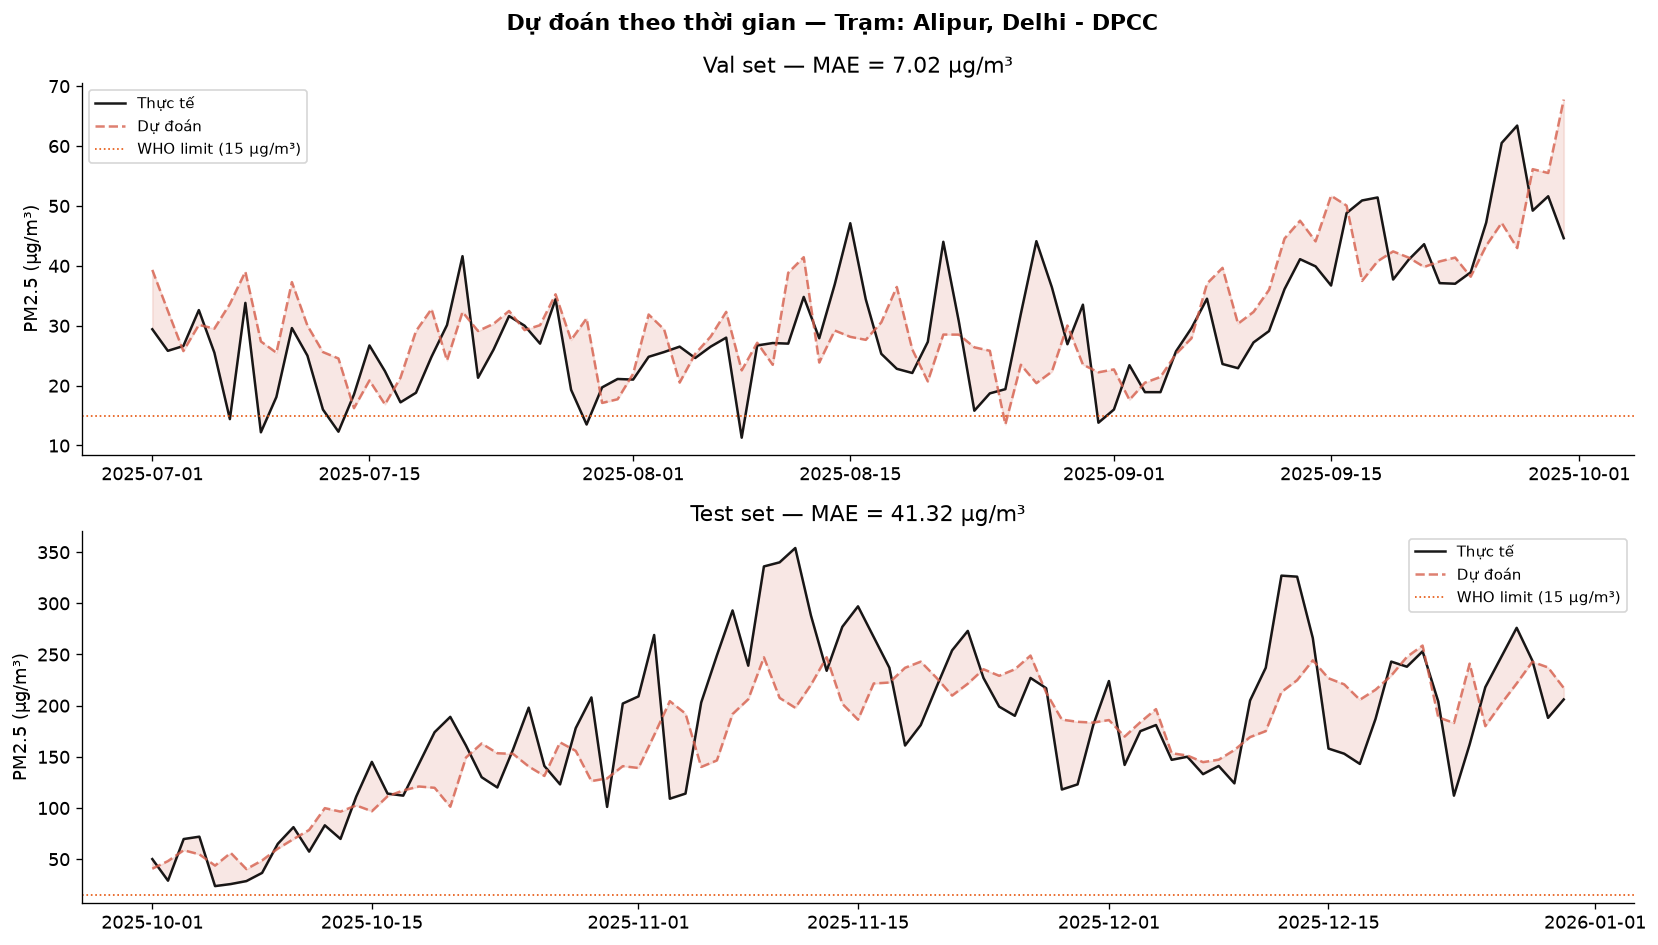

In [11]:
# Lấy 1 trạm cụ thể để vẽ timeline
station = val["location_name"].value_counts().index[0]  # trạm có nhiều data nhất

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
fig.suptitle(f"Dự đoán theo thời gian — Trạm: {station}", fontweight="bold")

for ax, split_name, df_split in [(axes[0], "Val", val), (axes[1], "Test", test)]:
    df_st = df_split[df_split["location_name"] == station].sort_values("date")
    if df_st.empty:
        ax.set_title(f"{split_name} — không có data cho trạm này")
        continue

    y_true = df_st["pm25_target"].values
    y_pred = lgbm_e3.predict(df_st[ALL_FEATS])
    dates  = df_st["date"].values

    ax.plot(dates, y_true, color="black",   linewidth=1.5, label="Thực tế",   alpha=0.9)
    ax.plot(dates, y_pred, color="#d6604d", linewidth=1.5, label="Dự đoán",   alpha=0.8, linestyle="--")
    ax.fill_between(dates, y_true, y_pred, alpha=0.15, color="#d6604d")

    # WHO threshold
    ax.axhline(15, color="#e6550d", linewidth=1, linestyle=":", label="WHO limit (15 µg/m³)")

    mae = mean_absolute_error(y_true, y_pred)
    ax.set_title(f"{split_name} set — MAE = {mae:.2f} µg/m³")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(ROOT / "reports/figures/timeline_prediction.png", bbox_inches="tight")
plt.show()

## 9. Tổng kết — Bảng kết quả cuối

In [12]:
summary_rows = []
for model_name in ["Persistence", "Ridge", "LightGBM Exp1", "LightGBM Exp2", "LightGBM Exp3"]:
    row = {"Model": model_name}
    for split in ["val", "test"]:
        m = metrics[(split, model_name)]
        row[f"{split}_MAE"]  = round(m["MAE"],  2)
        row[f"{split}_RMSE"] = round(m["RMSE"], 2)
        row[f"{split}_R2"]   = round(m["R2"],   3)
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)

# Highlight best
print("=" * 80)
print("TỔNG KẾT KẾT QUẢ")
print("=" * 80)
print(df_summary.to_string(index=False))
print("=" * 80)
print(f"\nModel tốt nhất (Val MAE): {df_summary.loc[df_summary['val_MAE'].idxmin(), 'Model']}")
print(f"Best Val MAE : {df_summary['val_MAE'].min()} µg/m³")
print(f"Best Test MAE: {df_summary.loc[df_summary['val_MAE'].idxmin(), 'test_MAE']} µg/m³")
print(f"\nWHO PM2.5 threshold: 15 µg/m³")
print(f"Val MAE / WHO threshold: {df_summary['val_MAE'].min() / 15 * 100:.1f}%")

TỔNG KẾT KẾT QUẢ
        Model  val_MAE  val_RMSE  val_R2  test_MAE  test_RMSE  test_R2
  Persistence    11.10     16.81  -0.112     54.25      75.77    0.320
        Ridge    15.05     19.05  -0.428     48.83      65.04    0.499
LightGBM Exp1     9.96     14.04   0.225     51.88      71.29    0.398
LightGBM Exp2     9.68     13.69   0.263     45.13      62.00    0.544
LightGBM Exp3     9.34     13.33   0.301     45.42      63.14    0.527

Model tốt nhất (Val MAE): LightGBM Exp3
Best Val MAE : 9.34 µg/m³
Best Test MAE: 45.42 µg/m³

WHO PM2.5 threshold: 15 µg/m³
Val MAE / WHO threshold: 62.3%
